In [3]:
%pip install pandas numpy scikit-learn matplotlib seaborn interpret ngboost catboost xgboost lightgbm shap lime streamlit ipykernel joblib

  Using cached pandas-3.1.0-cp312-cp312-macosx_11_0_arm64.whl.metadata (18 kB)
  Using cached numpy-2.5.4-cp312-cp312-macosx_14_0_arm64.whl.metadata (6.6 kB)
  Using cached scikit_learn-1.9.1-cp312-cp312-macosx_12_0_arm64.whl.metadata (9.3 kB)
  Using cached matplotlib-3.11.2-cp312-cp312-macosx_11_0_arm64.whl.metadata (80 kB)
  Using cached seaborn-0.13.2-py3-none-any.whl.metadata (5.4 kB)
  Using cached catboost-1.2.10-cp312-cp312-macosx_11_0_universal2.whl.metadata (1.4 kB)
  Using cached xgboost-3.4.1-py3-none-macosx_12_0_arm64.whl.metadata (2.0 kB)
  Using cached lightgbm-4.7.0-py3-none-macosx_12_0_arm64.whl.metadata (18 kB)
  Using cached shap-0.54.1-cp312-abi3-macosx_11_0_arm64.whl.metadata (23 kB)
  Using cached lime-0.2.0.1-py3-none-any.whl
  Using cached streamlit-1.66.1-py3-none-any.whl.metadata (10 kB)
  Using cached joblib-1.6.0-py3-none-any.whl.metadata (6.5 kB)
  Using cached scipy-1.18.1-cp312-cp312-macosx_14_0_arm64.whl.metadata (62 kB)
  Using cached threadpoolctl-3.7.

In [6]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import  ngboost, shap, lime
from sklearn.gaussian_process import GaussianProcessRegressor
import xgboost, lightgbm, catboost
pd.set_option("display.max_columns", 50)
DATA = "data/"

In [7]:
consumption = pd.read_csv(DATA + "monthly_consumption.csv")
household   = pd.read_csv(DATA + "w1_household_information_and_history.csv")
energy      = pd.read_csv(DATA + "w1_electricity_generation_water_heating_cooking.csv")
demographics= pd.read_csv(DATA + "w1_demographics.csv")
appliances  = pd.read_csv(DATA + "w1_appliances.csv")
ac          = pd.read_csv(DATA + "w1_ac_roster.csv")
fans        = pd.read_csv(DATA + "w1_fan_roster.csv")
lights      = pd.read_csv(DATA + "w1_light_roster.csv")
rooms       = pd.read_csv(DATA + "w1_room_roster.csv")

tables = {"consumption": consumption, "household": household, "energy": energy,
          "demographics": demographics, "appliances": appliances, "ac": ac,
          "fans": fans, "lights": lights, "rooms": rooms}

for name, df in tables.items():
    print(f"{name:13s} rows={len(df):>7,}  cols={df.shape[1]:>3}  households={df['household_ID'].nunique():,}")

consumption   rows=101,575  cols=  3  households=4,063
household     rows=  4,063  cols= 26  households=4,063
energy        rows=  4,063  cols= 36  households=4,063
demographics  rows= 16,270  cols= 16  households=4,063
appliances    rows= 53,599  cols=  4  households=4,055
ac            rows=  1,171  cols= 10  households=562
fans          rows= 13,525  cols=  6  households=3,817
lights        rows= 48,489  cols=  7  households=4,054
rooms         rows= 36,408  cols= 16  households=4,063


/var/folders/cq/0kdd600s33vgny_vzhnbctpr0000gn/T/ipykernel_93081/1662500487.py:9: DtypeWarning: Columns (9) have mixed types. Specify dtype option on import or set low_memory=False.
  rooms       = pd.read_csv(DATA + "w1_room_roster.csv")


In [8]:
print(consumption.dtypes)
print("Months:", consumption["month"].nunique(),
      "|", consumption["month"].min(), "to", consumption["month"].max())

# consumption is stored as text; some values have thousands separators like "1,644"
naive = pd.to_numeric(consumption["consumption"], errors="coerce")
print("Values that fail to parse as numbers:", (naive.isna() & consumption["consumption"].notna()).sum())

consumption["consumption"] = pd.to_numeric(
    consumption["consumption"].astype(str).str.replace(",", ""), errors="coerce")

print("Genuinely missing:", consumption["consumption"].isna().sum())
print("Zero readings:", (consumption["consumption"] == 0).sum())
consumption["consumption"].describe()

household_ID    object
month           object
consumption     object
dtype: object
Months: 25 | 2022-10-31 to 2024-10-31
Values that fail to parse as numbers: 57
Genuinely missing: 590
Zero readings: 2332


count    100985.000000
mean        122.144120
std         122.217922
min           0.000000
25%          60.000000
50%          96.000000
75%         148.000000
max        3025.000000
Name: consumption, dtype: float64

In [9]:
cons_ids = set(consumption["household_ID"])
print("Consumption households found in survey:",
      len(cons_ids & set(household["household_ID"])), "of", len(cons_ids))

Consumption households found in survey: 4063 of 4063


In [10]:
# A zero month almost always means a vacant house, a missed reading or a meter fault,
# not real household behaviour, so it shouldn't pull the average down.
zero_hh = consumption.loc[consumption["consumption"] == 0, "household_ID"].nunique()
print("Households with at least one zero month:", zero_hh)

consumption.loc[consumption["consumption"] == 0, "consumption"] = np.nan

Households with at least one zero month: 437


In [11]:
target = (consumption.groupby("household_ID")["consumption"]
          .agg(avg_kwh="mean", valid_months="count")
          .reset_index())

print(target["valid_months"].describe())

MIN_MONTHS = 12
before = len(target)
target = target[target["valid_months"] >= MIN_MONTHS].copy()
print(f"Kept {len(target):,} of {before:,} households "
      f"({before - len(target)} removed for having fewer than {MIN_MONTHS} valid months)")

count    4063.000000
mean       24.280827
std         2.947120
min         0.000000
25%        25.000000
50%        25.000000
75%        25.000000
max        25.000000
Name: valid_months, dtype: float64
Kept 3,999 of 4,063 households (64 removed for having fewer than 12 valid months)


In [12]:
target["log_kwh"] = np.log1p(target["avg_kwh"])

print("Mean kWh:  ", round(target["avg_kwh"].mean(), 1))
print("Median kWh:", round(target["avg_kwh"].median(), 1))
print("Skewness raw:", round(target["avg_kwh"].skew(), 2),
      "| after log:", round(target["log_kwh"].skew(), 2))
print("Min:", round(target["avg_kwh"].min(), 1), "| Max:", round(target["avg_kwh"].max(), 1))

Mean kWh:   124.7
Median kWh: 98.5
Skewness raw: 5.5 | after log: -0.51
Min: 1.2 | Max: 2154.4


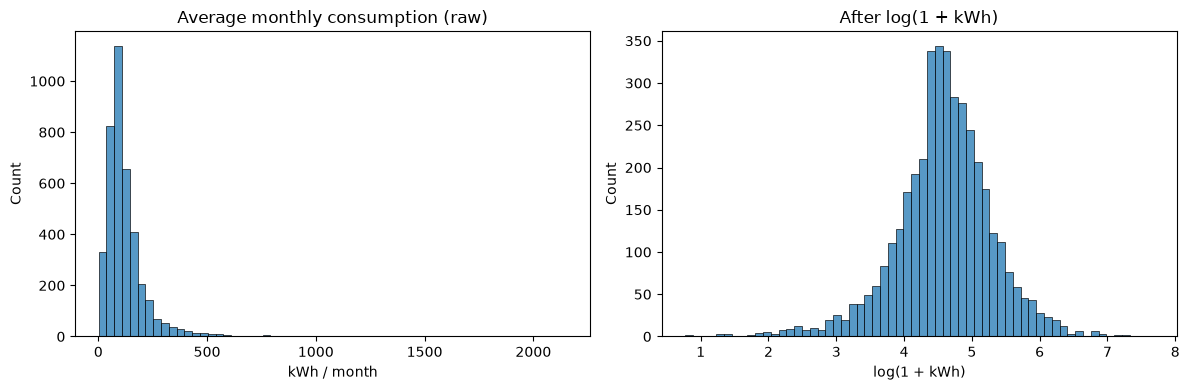

In [13]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4))
sns.histplot(target["avg_kwh"], bins=60, ax=axes[0])
axes[0].set(title="Average monthly consumption (raw)", xlabel="kWh / month")
sns.histplot(target["log_kwh"], bins=60, ax=axes[1])
axes[1].set(title="After log(1 + kWh)", xlabel="log(1 + kWh)")
plt.tight_layout()
plt.savefig("fig_target_distribution.png", dpi=150)
plt.show()

In [14]:
yes = lambda s: (s == "Yes").astype(int)

h = household[["household_ID"]].copy()
h["n_members"]       = household["no_of_household_members"]
h["floor_area"]      = household["floor_area"]
h["monthly_expenditure"] = household["total_monthly_expenditure_of_last_month"]
h["n_meters"]        = household["no_of_electricity_meters"]
h["has_business"]    = yes(household["is_there_business_carried_out_in_the_household"])
h["smart_meter"]     = (household["type_of_electricity_meter"] == "Smart meter").astype(int)
h["owns_house"]      = household["own_the_house_or_living_on_rent"].str.startswith("Yes").astype(int)
h["sec_class"]       = household["socio_economic_class"].map({"SEC E": 1, "SEC D": 2, "SEC C": 3, "SEC B": 4, "SEC A": 5})

house_map = {"Single House - Single Floor": "single_floor",
             "Single House - Double Floor": "double_floor",
             "Single House - More than 2 floors": "multi_floor",
             "Flat": "apartment", "Condominium/ Luxury apartments": "apartment"}
h["house_type"]  = household["type_of_house"].map(house_map).fillna("other")
h["built_year"]  = household["built_year_of_the_house"].replace("Don't know", "unknown")
h["wall_material"] = household["main_material_used_for_walls_of_the_house"].replace("I am not aware of that", "unknown")
h["roof_material"] = household["main_material_used_for_roof_of_the_house"].fillna("unknown")
h["area"]        = household["electricity_provider_csc_area"]
h.head()

,household_ID,n_members,floor_area,monthly_expenditure,n_meters,has_business,smart_meter,owns_house,sec_class,house_type,built_year,wall_material,roof_material,area
0,ID0001,4,1500.0,35000.0,1,0,0,1,3,double_floor,2000-2009,Brick,Asbestos,GALLE
1,ID0002,3,440.0,40000.0,1,0,0,1,2,single_floor,Before 1980,Brick,Asbestos,GALLE
2,ID0003,4,2500.0,250000.0,1,0,1,1,5,single_floor,1980-1989,Brick,Tile,GALLE
3,ID0004,4,2600.0,100000.0,1,0,1,1,5,double_floor,2010-2019,Cement Block,Concrete,BORALASGAMUWA
4,ID0005,2,480.0,60000.0,1,0,1,1,2,apartment,2010-2019,unknown,Concrete,KOLONNAWA


In [15]:
heat = energy["water_heating_method_for_bathing"]
water_heating = np.select(
    [heat.str.startswith("None"),
     heat.str.contains("solely by the grid"),
     heat.str.contains("solely by solar"),
     heat.str.contains("both by solar and the grid"),
     heat.str.contains("through an electric kettle"),
     heat.str.contains("gas, firewood")],
    ["none", "electric_inbuilt", "solar_inbuilt", "solar_and_grid", "electric_kettle", "non_electric"],
    default="other")

e = energy[["household_ID"]].copy()
e["has_solar"]       = yes(energy["generate_electicity_using_solar_energy"])
e["has_generator"]   = yes(energy["have_backup_generator"])
e["has_battery"]     = yes(energy["have_system_to_store_backup_energy"])
e["water_heating"]   = water_heating
e["cook_gas"]        = yes(energy["gas_used_for_cooking"])
e["cook_electric"]   = yes(energy["electricity_from_national_grid_used_for_cooking"])
e["cook_firewood"]   = yes(energy["firewood_used_for_cooking"])
e["boil_water_electric"] = energy["source_of_energy_for_boiling_drinking_water"].fillna("").str.startswith("Electricity").astype(int)
e["cooking_freq"]    = energy["no_of_times_food_cooked_last_week"].map(
    {"Did not cook at home last week": 0, "1-7 times": 1, "8 - 14 times": 2,
     "15 - 21 times": 3, "More than 21 times": 4})
e["water_heating"].value_counts()

water_heating
none                2457
non_electric         746
electric_inbuilt     507
solar_inbuilt        188
electric_kettle       99
solar_and_grid        52
other                 14
Name: count, dtype: int64

In [16]:
d = demographics
work_from_home = d["member_went_out_for_work_or_not_during_last_week"] == "No, worked from home"
employed = d["main_activity_engaged_in"].str.contains("economic activity", na=False) & \
           ~d["main_activity_engaged_in"].str.contains("not engaged", na=False)

demo = (d.assign(child=d["age"] < 15, elderly=d["age"] >= 65,
                 employed=employed, wfh=work_from_home)
          .groupby("household_ID")
          .agg(n_children=("child", "sum"), n_elderly=("elderly", "sum"),
               n_employed=("employed", "sum"), n_work_from_home=("wfh", "sum"),
               avg_hours_at_home=("no_of_hours_stayed_at_home_during_last_week", "mean"))
          .reset_index())
demo.describe().round(2)

,n_children,n_elderly,n_employed,n_work_from_home,avg_hours_at_home
count,4063.00,4063.00,4063.00,4063.00,4063.00
mean,0.68,0.57,1.52,0.21,125.14
std,0.93,0.76,1.02,0.55,32.37
min,0.00,0.00,0.00,0.00,0.00
25%,0.00,0.00,1.00,0.00,109.16
50%,0.00,0.00,1.00,0.00,130.33
75%,1.00,1.00,2.00,0.00,148.00
max,5.00,4.00,12.00,7.00,168.00


In [17]:
key_appliances = {
    "Refrigerator": "n_fridge", "Separate Freezer": "n_freezer",
    "Washing Machine": "n_washing_machine", "Clothes dryer": "n_dryer",
    "Electric Iron including electric steam iron": "n_iron", "TV": "n_tv",
    "Rice cooker": "n_rice_cooker", "Electric Kettle": "n_kettle",
    "Electric Oven": "n_oven", "Microwave": "n_microwave",
    "Electric cook tops (induction cookers, Infra-red cookers, hot plates)": "n_cooktop",
    "Air fryer": "n_air_fryer",
    "Geyser / Hot water systems for bathrooms which operate from electricity": "n_geyser",
    "Electric water heater to heat water for drinking purposes": "n_water_heater",
    "Electric Water pump": "n_water_pump", "Computers": "n_computer", "Laptops": "n_laptop",
    "CCTV camera systems": "n_cctv",
    "Electric vehicles (four wheelers) - cars,  vans, SUVs)": "n_ev",
}
app = (appliances[appliances["appliance_type"].isin(key_appliances)]
       .assign(col=lambda x: x["appliance_type"].map(key_appliances))
       .pivot_table(index="household_ID", columns="col", values="appliance_ID",
                    aggfunc="count", fill_value=0))
app["n_appliances_total"] = appliances.groupby("household_ID").size()
app = app.reset_index()
app.columns.name = None
app.shape

(4004, 21)

In [18]:
ac["hours_week"] = (ac["no_of_hours_ac_was_on_during_daytime_last_week"]
                    + ac["no_of_hours_ac_was_on_during_night_last_week"])
ac_f = (ac.assign(inverter=ac["is_the_ac_inverter_or_not"] == "Yes")
          .groupby("household_ID")
          .agg(n_ac=("ac_ID", "count"), n_ac_inverter=("inverter", "sum"),
               ac_hours_week=("hours_week", "sum"))
          .reset_index())

fans["hours_week"] = (fans["no_of_hours_fan_was_on_during_daytime_last_week"]
                      + fans["no_of_hours_fan_was_on_during_night_last_week"])
fan_f = (fans.groupby("household_ID")
             .agg(n_fans=("fan_ID", "count"), fan_hours_week=("hours_week", "sum"))
             .reset_index())
ac_f.describe().round(1)

,n_ac,n_ac_inverter,ac_hours_week
count,562.0,562.0,562.0
mean,2.1,1.3,40.9
std,2.6,1.6,83.8
min,1.0,0.0,0.0
25%,1.0,0.0,0.0
50%,1.0,1.0,14.0
75%,2.0,2.0,53.0
max,28.0,23.0,1162.0


In [19]:
# 0 W is not a real bulb wattage (it means "don't know"), so treat it as missing
# and fill with the typical wattage of that bulb type
lights["watt"] = lights["wattage_of_the_bulb"].replace(0, np.nan)
lights.loc[lights["watt"] > 200, "watt"] = np.nan   # >200 W for a household bulb is a data-entry error
typical_watt = lights.groupby("type_of_the_bulb")["watt"].transform("median")
lights["watt"] = lights["watt"].fillna(typical_watt)
lights["hours_week"] = (lights["no_of_hours_bulb_was_on_during_daytime_last_week"]
                        + lights["no_of_hours_bulb_was_on_during_night_last_week"])
lights["kwh_week"] = lights["watt"] * lights["hours_week"] / 1000
lights["inefficient"] = lights["type_of_the_bulb"].isin(
    ["Incandescent", "Halogen", "Tube Light (conventional)"])

light_f = (lights.groupby("household_ID")
                 .agg(n_bulbs=("light_ID", "count"), n_inefficient_bulbs=("inefficient", "sum"),
                      bulb_hours_week=("hours_week", "sum"), lighting_kwh_week=("kwh_week", "sum"))
                 .reset_index())

room_f = (rooms.assign(bedroom=rooms["main_purpose_of_the_room"] == "Bedrooms")
               .groupby("household_ID")
               .agg(n_rooms=("room_ID", "count"), n_bedrooms=("bedroom", "sum"))
               .reset_index())
light_f.describe().round(1)

,n_bulbs,n_inefficient_bulbs,bulb_hours_week,lighting_kwh_week
count,4054.0,4054.0,4054.0,4054.0
mean,12.0,0.5,216.9,3.4
std,13.6,4.0,623.4,23.6
min,1.0,0.0,0.0,0.0
25%,6.0,0.0,84.5,0.8
50%,8.0,0.0,134.2,1.4
75%,13.0,0.0,210.0,2.4
max,228.0,171.0,17409.8,929.4


In [20]:
df = target[["household_ID", "avg_kwh", "log_kwh"]]
for part in [h, e, demo, app, ac_f, fan_f, light_f, room_f]:
    df = df.merge(part, on="household_ID", how="left")

# a household missing from a roster owns none of those items -> 0, not missing
roster_cols = (list(app.columns) + list(ac_f.columns) + list(fan_f.columns)
               + list(light_f.columns) + list(room_f.columns))
roster_cols = [c for c in roster_cols if c != "household_ID"]
df[roster_cols] = df[roster_cols].fillna(0)

features = [c for c in df.columns if c not in ["household_ID", "avg_kwh", "log_kwh"]]
cat_features = [c for c in features if not pd.api.types.is_numeric_dtype(df[c])]
num_features = [c for c in features if c not in cat_features]

print("Modelling table:", df.shape)
print(f"{len(features)} features: {len(num_features)} numeric, {len(cat_features)} categorical")
print("Categorical:", cat_features)
print("\nColumns with missing values:")
print(df[features].isna().sum()[lambda s: s > 0])

df.to_csv("model_table.csv", index=False)

Modelling table: (3999, 61)
58 features: 52 numeric, 6 categorical
Categorical: ['house_type', 'built_year', 'wall_material', 'roof_material', 'area', 'water_heating']

Columns with missing values:
floor_area              26
monthly_expenditure    134
dtype: int64


In [21]:
q1, q3 = df["avg_kwh"].quantile([0.25, 0.75])
upper = q3 + 1.5 * (q3 - q1)
print(f"IQR upper fence: {upper:.1f} kWh")
print("Households above fence:", (df["avg_kwh"] > upper).sum())
print("Households above 1,000 kWh:", (df["avg_kwh"] > 1000).sum())

low = df[df["avg_kwh"] < 20]
print("\nHouseholds below 20 kWh:", len(low))
print(f"  no refrigerator: {(low['n_fridge'] == 0).mean():.0%} (all households: {(df['n_fridge'] == 0).mean():.0%})")
print(f"  have solar:      {low['has_solar'].mean():.0%} (all households: {df['has_solar'].mean():.0%})")
print(f"  avg SEC class:   {low['sec_class'].mean():.1f} (all households: {df['sec_class'].mean():.1f})")

IQR upper fence: 270.6 kWh
Households above fence: 256
Households above 1,000 kWh: 9

Households below 20 kWh: 113
  no refrigerator: 55% (all households: 15%)
  have solar:      3% (all households: 10%)
  avg SEC class:   2.8 (all households: 3.3)


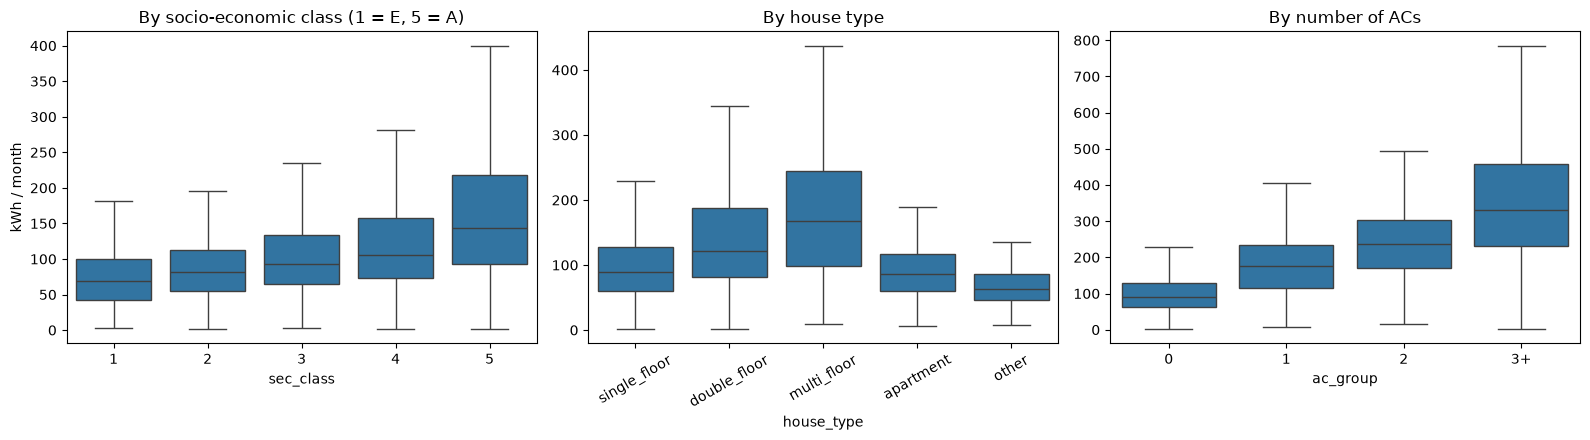

sec_class
1     69.4
2     81.8
3     93.3
4    105.1
5    143.2
Name: avg_kwh, dtype: float64


,households,median_kwh
ac_group,,
0,3441,91.0
1,310,175.0
2,123,238.0
3+,125,329.9


In [22]:
df["ac_group"] = df["n_ac"].clip(upper=3).astype(int).astype(str).replace("3", "3+")

fig, axes = plt.subplots(1, 3, figsize=(16, 4.5))
sns.boxplot(data=df, x="sec_class", y="avg_kwh", ax=axes[0], showfliers=False)
axes[0].set(title="By socio-economic class (1 = E, 5 = A)", ylabel="kWh / month")
order = ["single_floor", "double_floor", "multi_floor", "apartment", "other"]
sns.boxplot(data=df, x="house_type", y="avg_kwh", order=order, ax=axes[1], showfliers=False)
axes[1].set(title="By house type", ylabel="")
axes[1].tick_params(axis="x", rotation=30)
sns.boxplot(data=df, x="ac_group", y="avg_kwh", order=["0", "1", "2", "3+"], ax=axes[2], showfliers=False)
axes[2].set(title="By number of ACs", ylabel="")
plt.tight_layout()
plt.savefig("fig_groups.png", dpi=150)
plt.show()

print(df.groupby("sec_class")["avg_kwh"].median().round(1))
df.groupby("ac_group")["avg_kwh"].agg(households="count", median_kwh="median").round(1)

In [23]:
print(df.groupby("has_solar")["avg_kwh"].median().round(1))

profile = (df.groupby("has_solar")[["sec_class", "n_appliances_total", "n_ac", "n_rooms",
                                    "floor_area", "monthly_expenditure"]]
             .mean().T.round(1))
profile.columns = ["No solar", "Solar"]
profile

has_solar
0     93.5
1    209.2
Name: avg_kwh, dtype: float64


,No solar,Solar
sec_class,3.2,4.4
n_appliances_total,11.9,24.6
n_ac,0.1,1.8
n_rooms,8.5,12.9
floor_area,1266.0,2143.4
monthly_expenditure,67025.8,111601.3


n_appliances_total     0.50
n_rooms                0.41
n_fridge               0.40
n_washing_machine      0.39
n_bedrooms             0.36
monthly_expenditure    0.36
has_solar              0.33
n_laptop               0.32
n_ac_inverter          0.32
n_fans                 0.31
sec_class              0.31
n_ac                   0.31
n_microwave            0.30
n_bulbs                0.28
floor_area             0.26
Name: log_kwh, dtype: float64


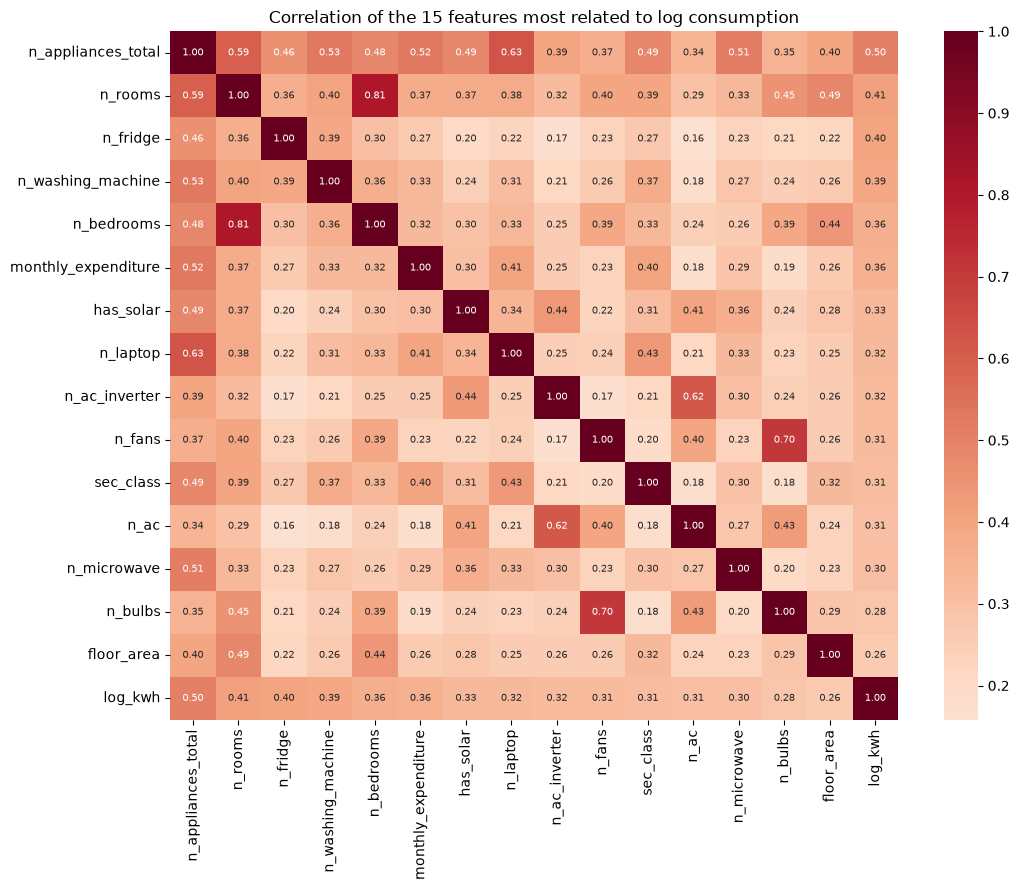

In [24]:
corr_with_target = df[num_features + ["log_kwh"]].corr()["log_kwh"].drop("log_kwh")
top15 = corr_with_target.abs().sort_values(ascending=False).head(15).index
print(corr_with_target[top15].round(2))

plt.figure(figsize=(11, 9))
sns.heatmap(df[list(top15) + ["log_kwh"]].corr(), annot=True, fmt=".2f",
            cmap="RdBu_r", center=0, annot_kws={"size": 7})
plt.title("Correlation of the 15 features most related to log consumption")
plt.tight_layout()
plt.savefig("fig_correlations.png", dpi=150)
plt.show()

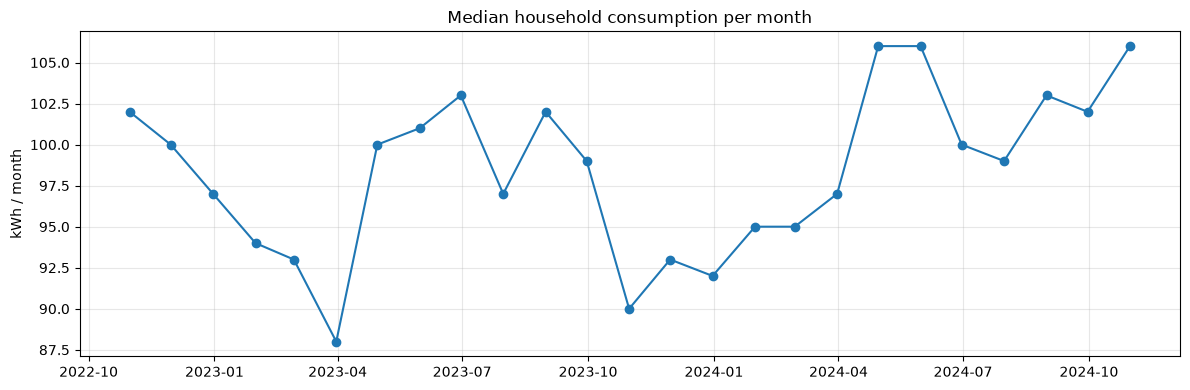

Lowest: Mar 2023 88.0 | Highest: Apr 2024 106.0


In [25]:
kept = consumption[consumption["household_ID"].isin(df["household_ID"])]
monthly = kept.groupby("month")["consumption"].median()
monthly.index = pd.to_datetime(monthly.index)

plt.figure(figsize=(12, 4))
plt.plot(monthly.index, monthly.values, marker="o")
plt.title("Median household consumption per month")
plt.ylabel("kWh / month")
plt.grid(alpha=0.3)
plt.tight_layout()
plt.savefig("fig_monthly.png", dpi=150)
plt.show()

print("Lowest:", monthly.idxmin().strftime("%b %Y"), monthly.min(),
      "| Highest:", monthly.idxmax().strftime("%b %Y"), monthly.max())

df = df.drop(columns="ac_group")   # helper column for plots only, not a feature

In [26]:
from sklearn.model_selection import train_test_split, KFold
from sklearn.pipeline import Pipeline
from sklearn.compose import ColumnTransformer
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import OneHotEncoder, StandardScaler

RANDOM_STATE = 42
DEMO_ID = "ID0128"

# removed before splitting, so it's never seen in training OR testing;
# used later to demonstrate a prediction + explanation in the report and app
demo_household = df[df["household_ID"] == DEMO_ID].copy()
model_df = df[df["household_ID"] != DEMO_ID].reset_index(drop=True)

demo_household[["household_ID", "avg_kwh", "n_members", "n_ac", "n_fridge",
                "n_appliances_total", "has_solar"]]

,household_ID,avg_kwh,n_members,n_ac,n_fridge,n_appliances_total,has_solar
122,ID0128,174.92,3,2.0,2.0,28.0,0


In [27]:
X = model_df[features]
y = model_df["log_kwh"]

# stratify on consumption deciles so low, medium and high users
# appear in the same proportions in train and test
deciles = pd.qcut(y, 10, labels=False)
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, stratify=deciles, random_state=RANDOM_STATE)

print(f"Train: {len(X_train):,}  Test: {len(X_test):,}")
print("Median kWh  train:", round(np.expm1(y_train).median(), 1),
      " test:", round(np.expm1(y_test).median(), 1))

Train: 3,198  Test: 800
Median kWh  train: 98.5  test: 98.6


In [28]:
def make_preprocessor(scale=False):
    num_steps = [("impute", SimpleImputer(strategy="median"))]
    if scale:   # needed for linear models and GPR; trees don't care about scale
        num_steps.append(("scale", StandardScaler()))
    return ColumnTransformer([
        ("num", Pipeline(num_steps), num_features),
        ("cat", OneHotEncoder(handle_unknown="infrequent_if_exist", min_frequency=20,
                              sparse_output=False), cat_features),
    ])

# validation = 5-fold cross-validation inside the training set
cv = KFold(n_splits=5, shuffle=True, random_state=RANDOM_STATE)

pre = make_preprocessor().fit(X_train)
print("Inputs after encoding:", pre.transform(X_train).shape[1])
print("Missing values after preprocessing:", np.isnan(pre.transform(X_test)).sum())

Inputs after encoding: 106
Missing values after preprocessing: 0


In [29]:
import time
from sklearn.model_selection import cross_validate
from sklearn.metrics import make_scorer, mean_absolute_error
from sklearn.dummy import DummyRegressor
from sklearn.linear_model import LinearRegression
from sklearn.ensemble import RandomForestRegressor
from xgboost import XGBRegressor
from lightgbm import LGBMRegressor
from catboost import CatBoostRegressor

def mae_kwh(y_true, y_pred):
    # models predict log(1 + kWh); convert back so the error is in real units
    return mean_absolute_error(np.expm1(y_true), np.expm1(y_pred))

scoring = {"r2": "r2", "mae_kwh": make_scorer(mae_kwh, greater_is_better=False)}
results = []

def evaluate_cv(name, model, scale=False, group="Benchmark (taught)"):
    pipe = Pipeline([("pre", make_preprocessor(scale)), ("model", model)])
    start = time.time()
    cv_res = cross_validate(pipe, X_train, y_train, cv=cv, scoring=scoring, n_jobs=-1)
    row = {"model": name, "group": group,
           "cv_r2": cv_res["test_r2"].mean(), "cv_r2_std": cv_res["test_r2"].std(),
           "cv_mae_kwh": -cv_res["test_mae_kwh"].mean(), "seconds": time.time() - start}
    results.append(row)
    print(f"{name:28s} CV R² {row['cv_r2']:.3f} ± {row['cv_r2_std']:.3f} | "
          f"CV MAE {row['cv_mae_kwh']:.1f} kWh | {row['seconds']:.0f}s")
    return pipe

In [30]:
benchmarks = {
    "Naive (training median)": (DummyRegressor(strategy="median"), False),
    "Linear Regression":       (LinearRegression(), True),
    "Random Forest":           (RandomForestRegressor(random_state=RANDOM_STATE, n_jobs=-1), False),
    "XGBoost":                 (XGBRegressor(random_state=RANDOM_STATE, n_jobs=-1), False),
    "LightGBM":                (LGBMRegressor(random_state=RANDOM_STATE, verbose=-1), False),
    "CatBoost":                (CatBoostRegressor(random_state=RANDOM_STATE, verbose=0), False),
}
for name, (model, scale) in benchmarks.items():
    evaluate_cv(name, model, scale)

Naive (training median)      CV R² -0.004 ± 0.004 | CV MAE 61.3 kWh | 2s
Linear Regression            CV R² 0.390 ± 0.070 | CV MAE 50.2 kWh | 1s
Random Forest                CV R² 0.411 ± 0.049 | CV MAE 44.3 kWh | 2s
XGBoost                      CV R² 0.337 ± 0.071 | CV MAE 48.1 kWh | 0s
LightGBM                     CV R² 0.395 ± 0.054 | CV MAE 45.0 kWh | 2s
CatBoost                     CV R² 0.425 ± 0.040 | CV MAE 43.7 kWh | 2s


In [31]:
pd.DataFrame(results).round(3)

,model,group,cv_r2,cv_r2_std,cv_mae_kwh,seconds
0,Naive (training median),Benchmark (taught),-0.004,0.004,61.306,1.835
1,Linear Regression,Benchmark (taught),0.390,0.070,50.166,0.904
2,Random Forest,Benchmark (taught),0.411,0.049,44.284,1.795
3,XGBoost,Benchmark (taught),0.337,0.071,48.113,0.159
4,LightGBM,Benchmark (taught),0.395,0.054,44.951,1.853
5,CatBoost,Benchmark (taught),0.425,0.040,43.674,2.264


In [54]:
from ngboost import NGBRegressor
from ngboost.distns import Normal
from sklearn.gaussian_process import GaussianProcessRegressor
from sklearn.gaussian_process.kernels import RBF, WhiteKernel, ConstantKernel as C
from ngb_compat import NGBoostRegressor   # the fix now lives in ngb_compat.py

In [33]:
# NGBoost: predicts a Normal distribution (mean + spread) of log consumption per household
ngb_default = NGBoostRegressor(Dist=Normal, random_state=RANDOM_STATE, verbose=False)
ngb_pipe = evaluate_cv("NGBoost (default)", ngb_default, scale=False, group="New algorithm")

# GPR: similarity kernel (RBF) + noise term; the kernel's settings are learned from the data
gpr_kernel = C(1.0) * RBF(length_scale=10.0) + WhiteKernel(noise_level=0.3)
gpr_default = GaussianProcessRegressor(kernel=gpr_kernel, normalize_y=True, random_state=RANDOM_STATE)
gpr_pipe = evaluate_cv("GPR (RBF kernel)", gpr_default, scale=True, group="New algorithm")

NGBoost (default)            CV R² 0.415 ± 0.047 | CV MAE 44.0 kWh | 18s
GPR (RBF kernel)             CV R² 0.420 ± 0.049 | CV MAE 43.8 kWh | 29s


In [34]:
(pd.DataFrame(results)
   .sort_values("cv_r2", ascending=False)
   .round(3))

,model,group,cv_r2,cv_r2_std,cv_mae_kwh,seconds
5,CatBoost,Benchmark (taught),0.425,0.040,43.674,2.264
7,GPR (RBF kernel),New algorithm,0.420,0.049,43.756,29.046
6,NGBoost (default),New algorithm,0.415,0.047,43.979,18.313
2,Random Forest,Benchmark (taught),0.411,0.049,44.284,1.795
4,LightGBM,Benchmark (taught),0.395,0.054,44.951,1.853
1,Linear Regression,Benchmark (taught),0.390,0.070,50.166,0.904
3,XGBoost,Benchmark (taught),0.337,0.071,48.113,0.159
0,Naive (training median),Benchmark (taught),-0.004,0.004,61.306,1.835


In [35]:
X_demo = demo_household[features]
actual = demo_household["avg_kwh"].iloc[0]

ngb_pipe.fit(X_train, y_train)
dist = ngb_pipe["model"].pred_dist(ngb_pipe["pre"].transform(X_demo))
mu, sigma = dist.params["loc"][0], dist.params["scale"][0]

gpr_pipe.fit(X_train, y_train)
g_mu, g_sd = gpr_pipe["model"].predict(gpr_pipe["pre"].transform(X_demo), return_std=True)
g_mu, g_sd = g_mu[0], g_sd[0]

print(f"Demo household {DEMO_ID}: actual {actual:.1f} kWh")
for name, m, s in [("NGBoost", mu, sigma), ("GPR", g_mu, g_sd)]:
    lo, hi = np.expm1(m - 1.645 * s), np.expm1(m + 1.645 * s)
    print(f"  {name:8s} predicts {np.expm1(m):6.1f} kWh   90% range {lo:6.1f} – {hi:6.1f} kWh")
print("GPR learned kernel:", gpr_pipe["model"].kernel_)

Demo household ID0128: actual 174.9 kWh
  NGBoost  predicts  242.0 kWh   90% range  127.5 –  458.5 kWh
  GPR      predicts  215.0 kWh   90% range   85.4 –  539.0 kWh
GPR learned kernel: 1.15**2 * RBF(length_scale=14.4) + WhiteKernel(noise_level=0.517)


In [36]:
from sklearn.model_selection import RandomizedSearchCV
from sklearn.tree import DecisionTreeRegressor
from sklearn.gaussian_process.kernels import Matern, RationalQuadratic
from scipy.stats import randint, uniform, loguniform

def record_search(name, search, group):
    i = search.best_index_
    r = search.cv_results_
    row = {"model": name, "group": group,
           "cv_r2": r["mean_test_r2"][i], "cv_r2_std": r["std_test_r2"][i],
           "cv_mae_kwh": -r["mean_test_mae_kwh"][i], "seconds": search.refit_time_}
    results.append(row)
    print(f"{name:28s} CV R² {row['cv_r2']:.3f} ± {row['cv_r2_std']:.3f} | CV MAE {row['cv_mae_kwh']:.1f} kWh")
    for k, v in search.best_params_.items():
        print(f"    {k.replace('model__', ''):15s} {v}")

In [37]:
def tree(depth, leaf):
    return DecisionTreeRegressor(criterion="friedman_mse", max_depth=depth,
                                 min_samples_leaf=leaf, random_state=RANDOM_STATE)

ngb_space = {
    "model__n_estimators":   randint(300, 1500),
    "model__learning_rate":  loguniform(0.005, 0.1),
    "model__minibatch_frac": uniform(0.5, 0.5),   # 50–100% of rows per boosting step
    "model__col_sample":     uniform(0.3, 0.7),   # 30–100% of features per boosting step
    "model__Base": [tree(d, l) for d in (2, 3, 4, 5) for l in (5, 15, 30)],
}
ngb_search = RandomizedSearchCV(
    Pipeline([("pre", make_preprocessor()),
              ("model", NGBoostRegressor(Dist=Normal, random_state=RANDOM_STATE, verbose=False))]),
    ngb_space, n_iter=20, cv=cv, scoring=scoring, refit="r2",
    n_jobs=-1, random_state=RANDOM_STATE)
ngb_search.fit(X_train, y_train)
record_search("NGBoost (tuned)", ngb_search, "New algorithm")

/Users/chamathka/Uni Stuff/Semester 2/Applied machine learning/Assignment II/.venv/lib/python3.12/site-packages/sklearn/tree/_classes.py:1347: FutureWarning: Value `"friedman_mse"` for `criterion` is deprecated and will be removed in 1.11. It maps to `"squared_error"` as both were always equivalent. Use `criterion="squared_error"` to remove this warning.
  warnings.warn(


NGBoost (tuned)              CV R² 0.429 ± 0.041 | CV MAE 43.3 kWh
    Base            DecisionTreeRegressor(max_depth=4, min_samples_leaf=15, random_state=42)
    col_sample      0.5764170627228988
    learning_rate   0.012045003291616438
    minibatch_frac  0.5070399113575422
    n_estimators    892


In [38]:
# GPR has no trees to tune: its kernel's own parameters (length scale, noise)
# are optimised automatically by maximising the marginal likelihood.
# The real choice is the kernel family, so we compare four.
kernels = {
    "RBF":                C(1.0) * RBF(length_scale=10.0) + WhiteKernel(0.3),
    "Matern (nu=1.5)":    C(1.0) * Matern(length_scale=10.0, nu=1.5) + WhiteKernel(0.3),
    "Matern (nu=2.5)":    C(1.0) * Matern(length_scale=10.0, nu=2.5) + WhiteKernel(0.3),
    "Rational quadratic": C(1.0) * RationalQuadratic(length_scale=10.0, alpha=1.0) + WhiteKernel(0.3),
}
for name, k in kernels.items():
    evaluate_cv(f"GPR {name}", GaussianProcessRegressor(kernel=k, normalize_y=True,
                random_state=RANDOM_STATE), scale=True, group="New algorithm")

GPR RBF                      CV R² 0.420 ± 0.049 | CV MAE 43.8 kWh | 29s
GPR Matern (nu=1.5)          CV R² 0.424 ± 0.046 | CV MAE 43.4 kWh | 31s
GPR Matern (nu=2.5)          CV R² 0.423 ± 0.047 | CV MAE 43.5 kWh | 30s
GPR Rational quadratic       CV R² 0.424 ± 0.045 | CV MAE 43.5 kWh | 57s


In [39]:
cat_space = {
    "model__iterations":    randint(300, 1200),
    "model__learning_rate": loguniform(0.01, 0.1),
    "model__depth":         randint(4, 9),
    "model__l2_leaf_reg":   loguniform(1, 10),
    "model__rsm":           uniform(0.5, 0.5),
}
cat_search = RandomizedSearchCV(
    Pipeline([("pre", make_preprocessor()),
              ("model", CatBoostRegressor(random_state=RANDOM_STATE, verbose=0, thread_count=1))]),
    cat_space, n_iter=25, cv=cv, scoring=scoring, refit="r2",
    n_jobs=-1, random_state=RANDOM_STATE)
cat_search.fit(X_train, y_train)
record_search("CatBoost (tuned)", cat_search, "Benchmark (taught)")

CatBoost (tuned)             CV R² 0.434 ± 0.044 | CV MAE 43.4 kWh
    depth           8
    iterations      1091
    l2_leaf_reg     2.273805573563182
    learning_rate   0.01909565280104538
    rsm             0.7713480415791243


In [40]:
(pd.DataFrame(results)
   .sort_values("cv_r2", ascending=False)
   .round(3))

,model,group,cv_r2,cv_r2_std,cv_mae_kwh,seconds
13,CatBoost (tuned),Benchmark (taught),0.434,0.044,43.355,9.480
8,NGBoost (tuned),New algorithm,0.429,0.041,43.250,10.934
5,CatBoost,Benchmark (taught),0.425,0.040,43.674,2.264
10,GPR Matern (nu=1.5),New algorithm,0.424,0.046,43.396,30.760
12,GPR Rational quadratic,New algorithm,0.424,0.045,43.497,56.978
11,GPR Matern (nu=2.5),New algorithm,0.423,0.047,43.509,29.861
7,GPR (RBF kernel),New algorithm,0.420,0.049,43.756,29.046
9,GPR RBF,New algorithm,0.420,0.049,43.756,29.214
6,NGBoost (default),New algorithm,0.415,0.047,43.979,18.313
2,Random Forest,Benchmark (taught),0.411,0.049,44.284,1.795


In [41]:
from sklearn.metrics import r2_score, mean_squared_error, median_absolute_error
from scipy.stats import norm
from sklearn.base import clone

final_model = ngb_search.best_estimator_      # selected model
cat_final   = cat_search.best_estimator_      # best taught benchmark, for context
gpr_final   = Pipeline([("pre", make_preprocessor(scale=True)),
                        ("model", GaussianProcessRegressor(
                            kernel=C(1.0) * Matern(length_scale=10.0, nu=1.5) + WhiteKernel(0.3),
                            normalize_y=True, random_state=RANDOM_STATE))]).fit(X_train, y_train)
lin_final   = Pipeline([("pre", make_preprocessor(scale=True)),
                        ("model", LinearRegression())]).fit(X_train, y_train)

In [42]:
def test_metrics(name, pred_log):
    actual, pred = np.expm1(y_test), np.expm1(pred_log)
    rel = np.abs(pred - actual) / actual
    return {"model": name,
            "test_r2_log": r2_score(y_test, pred_log),
            "rmse_kwh": np.sqrt(mean_squared_error(actual, pred)),
            "mae_kwh": mean_absolute_error(actual, pred),
            "median_ae_kwh": median_absolute_error(actual, pred),
            "within_25pct": (rel <= 0.25).mean(),
            "within_50pct": (rel <= 0.50).mean()}

pred_ngb = final_model.predict(X_test)
test_table = pd.DataFrame([
    test_metrics("NGBoost (tuned) — selected", pred_ngb),
    test_metrics("CatBoost (tuned)", cat_final.predict(X_test)),
    test_metrics("GPR (Matern 1.5)", gpr_final.predict(X_test)),
    test_metrics("Linear Regression", lin_final.predict(X_test)),
    test_metrics("Naive (training median)", np.full(len(y_test), y_train.median())),
]).round(3)
test_table

,model,test_r2_log,rmse_kwh,mae_kwh,median_ae_kwh,within_25pct,within_50pct
0,NGBoost (tuned) — selected,0.427,105.113,45.721,23.952,0.502,0.778
1,CatBoost (tuned),0.427,105.808,45.403,24.502,0.505,0.776
2,GPR (Matern 1.5),0.433,105.909,45.808,23.960,0.504,0.772
3,Linear Regression,0.400,139.740,51.871,24.984,0.495,0.765
4,Naive (training median),-0.001,126.503,63.371,38.840,0.344,0.622


         households  median_actual  median_predicted    mae  \
band                                                          
0–60            172           42.4              62.9   32.6   
61–90           175           77.9              84.0   18.7   
91–180          325          121.7             103.8   29.5   
181–300          88          219.3             152.9   76.2   
300+             40          402.8             218.2  285.0   

         mae_pct_of_typical  
band                         
0–60                   77.0  
61–90                  24.0  
91–180                 24.0  
181–300                35.0  
300+                   71.0  


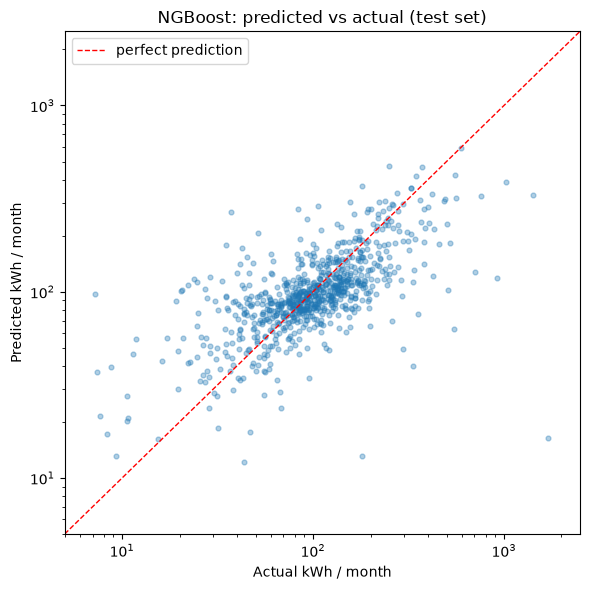

In [43]:
actual_kwh, pred_kwh = np.expm1(y_test), np.expm1(pred_ngb)
bands = pd.cut(actual_kwh, [0, 60, 90, 180, 300, np.inf],
               labels=["0–60", "61–90", "91–180", "181–300", "300+"])
band_table = (pd.DataFrame({"band": bands, "actual": actual_kwh, "pred": pred_kwh,
                            "abs_err": np.abs(pred_kwh - actual_kwh)})
                .groupby("band", observed=True)
                .agg(households=("actual", "size"), median_actual=("actual", "median"),
                     median_predicted=("pred", "median"), mae=("abs_err", "mean"))
                .round(1))
band_table["mae_pct_of_typical"] = (band_table["mae"] / band_table["median_actual"] * 100).round(0)
print(band_table)

fig, ax = plt.subplots(figsize=(6, 6))
ax.scatter(actual_kwh, pred_kwh, alpha=0.35, s=12)
lims = [5, 2500]
ax.plot(lims, lims, "r--", lw=1, label="perfect prediction")
ax.set(xscale="log", yscale="log", xlim=lims, ylim=lims, xlabel="Actual kWh / month",
       ylabel="Predicted kWh / month", title="NGBoost: predicted vs actual (test set)")
ax.legend()
plt.tight_layout()
plt.savefig("fig_pred_vs_actual.png", dpi=150)
plt.show()

In [44]:
def coverage_table(mu, sigma):
    rows = []
    for level in [0.50, 0.80, 0.90, 0.95]:
        z = norm.ppf(0.5 + level / 2)
        lo, hi = mu - z * sigma, mu + z * sigma
        rows.append({"interval": f"{level:.0%}",
                     "actual_coverage": round(((y_test >= lo) & (y_test <= hi)).mean(), 3),
                     "median_width_kwh": round(np.median(np.expm1(hi) - np.expm1(lo)), 1)})
    return pd.DataFrame(rows)

dist = final_model["model"].pred_dist(final_model["pre"].transform(X_test))
mu, sigma = dist.params["loc"], dist.params["scale"]
print(coverage_table(mu, sigma))
print("Correlation between predicted uncertainty and actual error:",
      round(np.corrcoef(sigma, np.abs(y_test - mu))[0, 1], 2))

  interval  actual_coverage  median_width_kwh
0      50%            0.470              46.3
1      80%            0.739              90.0
2      90%            0.810             117.9
3      95%            0.868             143.8
Correlation between predicted uncertainty and actual error: 0.32


In [45]:
# Out-of-fold check on the TRAINING set: how much wider must the ranges be
# so that 90% of households really fall inside the 90% range?
oof_z = np.zeros(len(y_train))
for tr, va in cv.split(X_train):
    m = clone(final_model).fit(X_train.iloc[tr], y_train.iloc[tr])
    d = m["model"].pred_dist(m["pre"].transform(X_train.iloc[va]))
    oof_z[va] = np.abs(y_train.iloc[va].values - d.params["loc"]) / d.params["scale"]

SCALE_FACTOR = np.quantile(oof_z, 0.90) / norm.ppf(0.95)
print(f"Uncertainty scale factor (learned on training folds): {SCALE_FACTOR:.3f}")
coverage_table(mu, sigma * SCALE_FACTOR)

Uncertainty scale factor (learned on training folds): 1.369


,interval,actual_coverage,median_width_kwh
0,50%,0.599,64.0
1,80%,0.839,126.8
2,90%,0.906,170.5
3,95%,0.935,213.5


In [46]:
# Upper reference: predict each test household's 2nd-year average from its OWN 1st-year meter readings
months = sorted(consumption["month"].unique())
year1, year2 = months[:12], months[12:24]
test_ids = model_df.loc[X_test.index, "household_ID"]
c = consumption[consumption["household_ID"].isin(test_ids)]
y1 = c[c["month"].isin(year1)].groupby("household_ID")["consumption"].mean()
y2 = c[c["month"].isin(year2)].groupby("household_ID")["consumption"].mean()
both = pd.concat([y1, y2], axis=1, keys=["y1", "y2"]).dropna()
print(f"Year 2 predicted from the same household's year 1 average: "
      f"MAE {mean_absolute_error(both['y2'], both['y1']):.1f} kWh ({len(both)} test households)")

Year 2 predicted from the same household's year 1 average: MAE 21.8 kWh (800 test households)


In [47]:
import shap

pre, ngb = final_model["pre"], final_model["model"]
names = [n.split("__", 1)[1] for n in pre.get_feature_names_out()]   # tidy names, e.g. "n_ac"
X_test_t = pd.DataFrame(pre.transform(X_test), columns=names)

# model_output=0 -> explain the predicted MEAN (log kWh); exact for tree models
explainer = shap.TreeExplainer(ngb, model_output=0)
shap_values = explainer(X_test_t)
print(f"Base value (average prediction): {np.expm1(shap_values.base_values[0]):.1f} kWh")

Base value (average prediction): 96.6 kWh


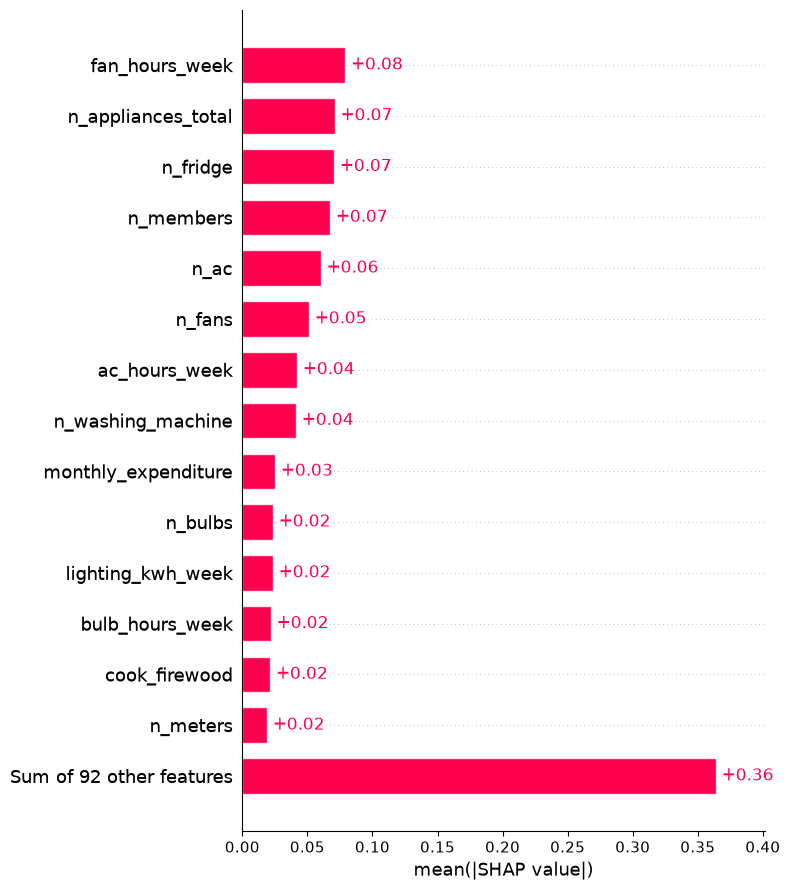

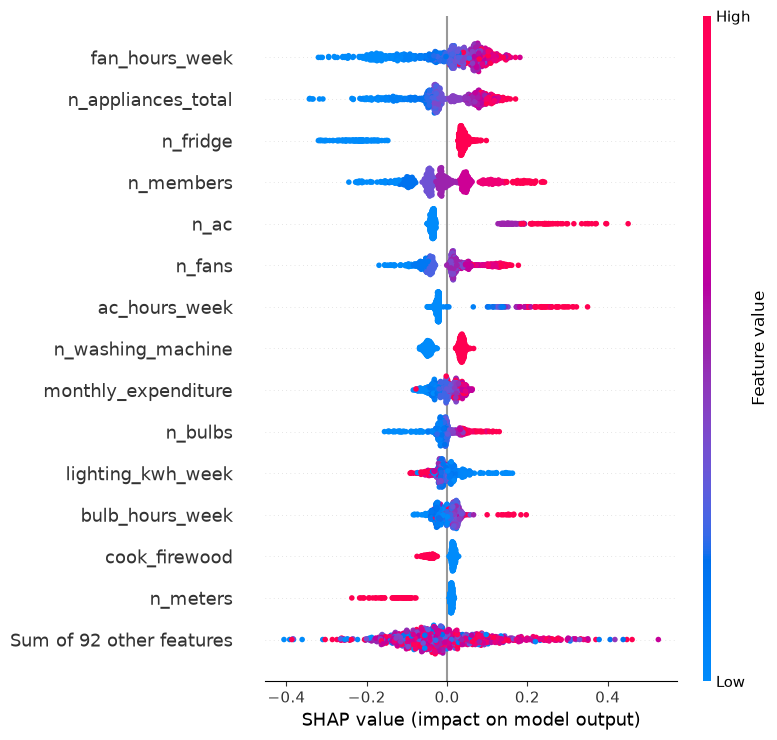

In [48]:
shap.plots.bar(shap_values, max_display=15, show=False)
plt.tight_layout(); plt.savefig("fig_shap_bar.png", dpi=150); plt.show()

shap.plots.beeswarm(shap_values, max_display=15, show=False)
plt.tight_layout(); plt.savefig("fig_shap_beeswarm.png", dpi=150); plt.show()

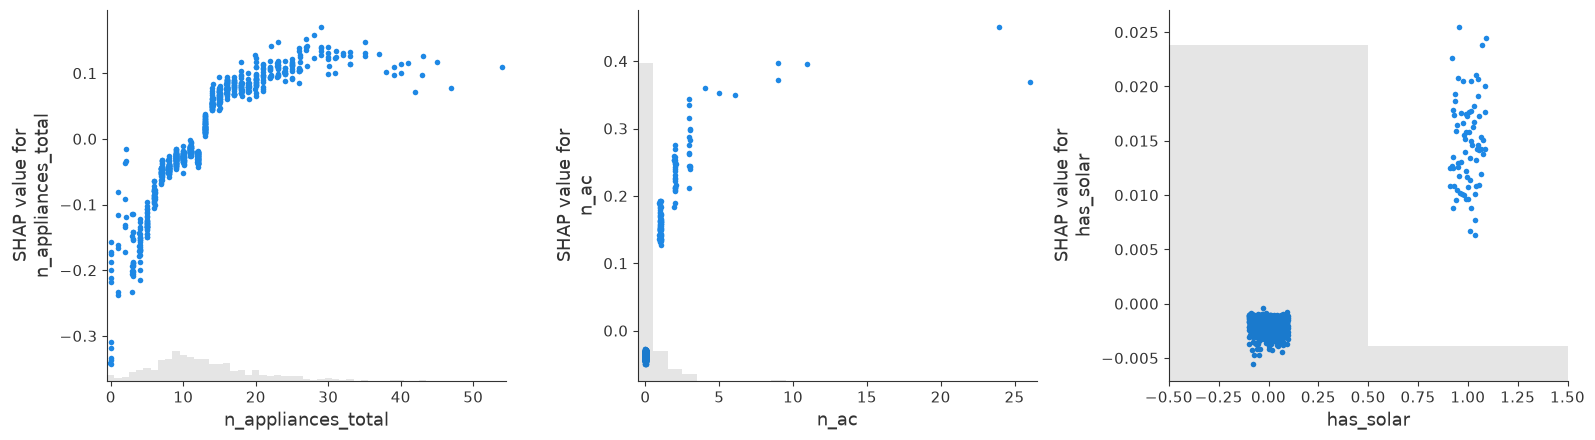

n_fridge = 0: average effect -20%  (127 test homes)
n_ac = 1: average effect +17%  (65 test homes)
n_ac = 2: average effect +26%  (26 test homes)
n_ac = 3: average effect +32%  (15 test homes)
has_solar = 1: average effect +1%  (75 test homes)
cook_firewood = 1: average effect -4%  (177 test homes)


In [49]:
fig, axes = plt.subplots(1, 3, figsize=(16, 4.5))
for ax, f in zip(axes, ["n_appliances_total", "n_ac", "has_solar"]):
    shap.plots.scatter(shap_values[:, f], ax=ax, show=False)
plt.tight_layout(); plt.savefig("fig_shap_dependence.png", dpi=150); plt.show()

# the model predicts log(kWh), so a SHAP value s means "x (e^s - 1) %"
def effect(feature, value):
    mask = X_test_t[feature] == value
    return (np.exp(shap_values[:, feature].values[mask].mean()) - 1) * 100

for f, v in [("n_fridge", 0), ("n_ac", 1), ("n_ac", 2), ("n_ac", 3),
             ("has_solar", 1), ("cook_firewood", 1)]:
    print(f"{f} = {v}: average effect {effect(f, v):+.0f}%  ({(X_test_t[f] == v).sum()} test homes)")

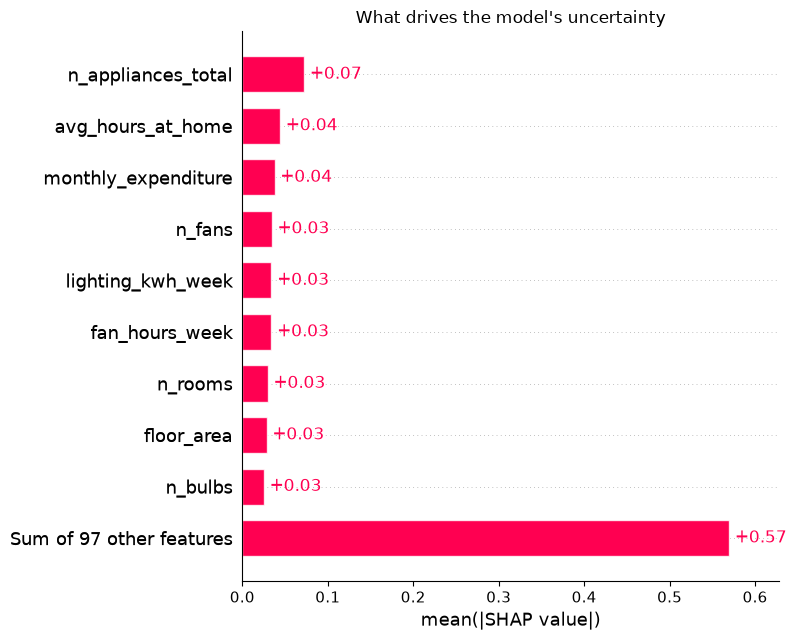

In [50]:
# model_output=1 -> explain the predicted SPREAD (log of the standard deviation)
unc_explainer = shap.TreeExplainer(ngb, model_output=1)
unc_values = unc_explainer(X_test_t)
shap.plots.bar(unc_values, max_display=10, show=False)
plt.title("What drives the model's uncertainty")
plt.tight_layout(); plt.savefig("fig_shap_uncertainty.png", dpi=150); plt.show()

ID0128: actual 174.9 kWh | predicted 254.5 kWh | 80% range 163.3–396.4 kWh
                     122
n_members            3.0
n_ac                 2.0
ac_hours_week        7.0
n_fridge             2.0
n_fans               8.0
n_appliances_total  28.0


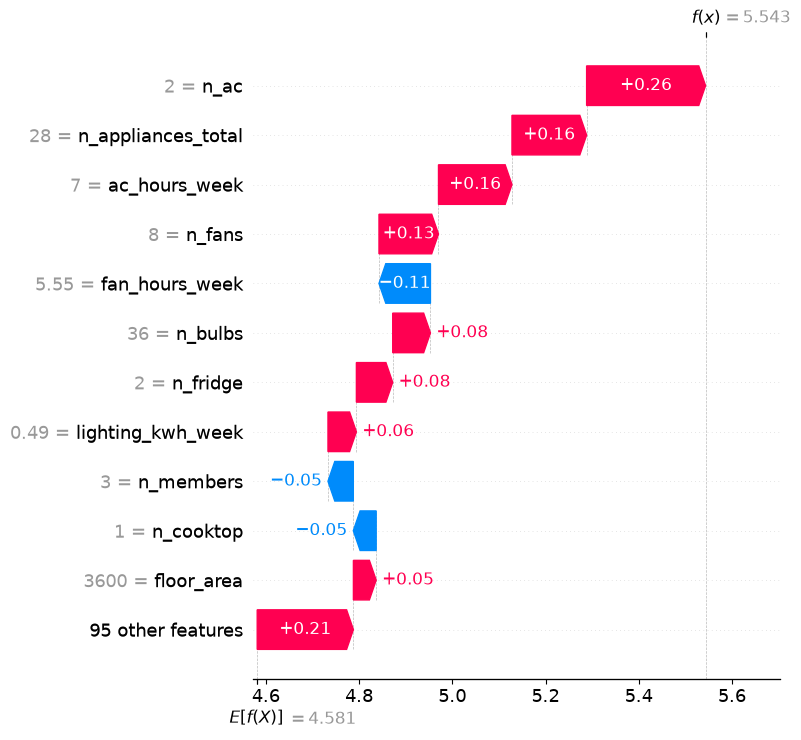

In [51]:
X_demo_t = pd.DataFrame(pre.transform(demo_household[features]), columns=names)
d = ngb.pred_dist(X_demo_t.values)
m, s = d.params["loc"][0], d.params["scale"][0] * SCALE_FACTOR
z80 = norm.ppf(0.90)
print(f"{DEMO_ID}: actual {demo_household['avg_kwh'].iloc[0]:.1f} kWh | "
      f"predicted {np.expm1(m):.1f} kWh | 80% range {np.expm1(m - z80*s):.1f}–{np.expm1(m + z80*s):.1f} kWh")
print(demo_household[["n_members", "n_ac", "ac_hours_week", "n_fridge", "n_fans", "n_appliances_total"]].T)

demo_sv = explainer(X_demo_t)
shap.plots.waterfall(demo_sv[0], max_display=12, show=False)
plt.tight_layout(); plt.savefig("fig_shap_waterfall_demo.png", dpi=150); plt.show()
shap_top = pd.Series(demo_sv.values[0], index=names).abs().sort_values(ascending=False).head(10)

In [52]:
import re
from lime.lime_tabular import LimeTabularExplainer

lime_explainer = LimeTabularExplainer(pre.transform(X_train), feature_names=names,
                                      mode="regression", random_state=RANDOM_STATE)
exp = lime_explainer.explain_instance(X_demo_t.values[0], ngb.predict,
                                      num_features=10, num_samples=5000)

lime_table = pd.DataFrame(exp.as_list(), columns=["rule", "effect_log"])
lime_table["effect_pct"] = ((np.exp(lime_table["effect_log"]) - 1) * 100).round(0)
print(lime_table[["rule", "effect_pct"]])

def feature_in(rule):
    hits = [n for n in names if re.search(r"(^|\s)" + re.escape(n) + r"(\s|$)", rule)]
    return max(hits, key=len)

agree = {feature_in(r) for r in lime_table["rule"]} & set(shap_top.index)
print(f"\nSHAP and LIME agree on {len(agree)} of their top 10 features: {sorted(agree)}")

                         rule  effect_pct
0        ac_hours_week > 0.00        30.0
1                 n_ac > 0.00        29.0
2        has_business <= 0.00       -16.0
3            n_meters <= 1.00        19.0
4     fan_hours_week <= 33.25       -14.0
5       has_generator <= 0.00       -13.0
6           n_members <= 3.00       -12.0
7  n_appliances_total > 17.00        12.0
8               n_fans > 4.00        12.0
9             n_fridge > 1.00        11.0

SHAP and LIME agree on 7 of their top 10 features: ['ac_hours_week', 'fan_hours_week', 'n_ac', 'n_appliances_total', 'n_fans', 'n_fridge', 'n_members']


In [55]:
import pickle, sklearn, ngboost
import ngb_compat

# point the fitted model at the class in ngb_compat.py so the app can load it
final_model["model"].__class__ = ngb_compat.NGBoostRegressor

defaults = {c: (float(X_train[c].median()) if c in num_features else X_train[c].mode()[0])
            for c in features}
ngb_row = test_table.iloc[0]
calibrated = coverage_table(mu, sigma * SCALE_FACTOR)

bundle = {
    "pipeline": final_model,
    "features": features,
    "num_features": num_features,
    "cat_features": cat_features,
    "cat_options": {c: sorted(X_train[c].dropna().unique().tolist()) for c in cat_features},
    "defaults": defaults,
    "scale_factor": float(SCALE_FACTOR),
    "metrics": {"test_mae_kwh": float(ngb_row["mae_kwh"]),
                "test_median_ae_kwh": float(ngb_row["median_ae_kwh"]),
                "test_r2_log": float(ngb_row["test_r2_log"]),
                "coverage_80": float(calibrated.loc[1, "actual_coverage"])},
    "demo": demo_household[features + ["household_ID", "avg_kwh"]].iloc[0].to_dict(),
    "versions": {"scikit-learn": sklearn.__version__, "ngboost": ngboost.__version__,
                 "shap": shap.__version__, "numpy": np.__version__, "pandas": pd.__version__},
}
with open("electricity_model.pkl", "wb") as f:
    pickle.dump(bundle, f)
print("Saved electricity_model.pkl")
print(bundle["metrics"])

Saved electricity_model.pkl
{'test_mae_kwh': 45.721, 'test_median_ae_kwh': 23.952, 'test_r2_log': 0.427, 'coverage_80': 0.839}


In [56]:
with open("electricity_model.pkl", "rb") as f:
    loaded = pickle.load(f)

demo_X = pd.DataFrame([loaded["demo"]])[loaded["features"]]
print("Reloaded model, demo household:", round(np.expm1(loaded["pipeline"].predict(demo_X)[0]), 1), "kWh")
default_X = pd.DataFrame([loaded["defaults"]])[loaded["features"]]
print("Household built from defaults: ", round(np.expm1(loaded["pipeline"].predict(default_X)[0]), 1), "kWh")

Reloaded model, demo household: 254.5 kWh
Household built from defaults:  89.7 kWh


In [57]:
from importlib.metadata import version
pkgs = ["streamlit", "numpy", "pandas", "scipy", "scikit-learn", "ngboost", "shap", "altair"]
with open("requirements.txt", "w") as f:
    f.write("\n".join(f"{p}=={version(p)}" for p in pkgs) + "\n")
print(open("requirements.txt").read())

streamlit==1.66.1
numpy==2.5.4
pandas==2.3.3
scipy==1.18.1
scikit-learn==1.9.1
ngboost==0.5.11
shap==0.54.1
altair==6.3.0

